In [1]:
# import needed modules/libraries
import os, pysam
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from tqdm import tqdm

In [2]:
anno = pd.read_table("/lustre/bio_running/GTEx_Long_Project/gencode.v49.basic.annotation.gtf.chrM.gtf.lengths_info.tsv")
anno["len"] = (anno["stop"] - anno["start"]) + 1
anno["gene_type"] = anno["gene_type"].apply(lambda x: x[1:-1])
anno["gene_name"] = anno["gene_name"].apply(lambda x: x[1:-1])
anno

,Region,track,start,stop,strand,attributes,gene_ids,gene_type,gene_name,len
0,chrM,gene,577,647,+,"gene_id ""ENSG00000210049.1""; gene_type ""Mt_tRN...","""ENSG00000210049.1""",Mt_tRNA,MT-TF,71
1,chrM,gene,648,1601,+,"gene_id ""ENSG00000211459.2""; gene_type ""Mt_rRN...","""ENSG00000211459.2""",Mt_rRNA,MT-RNR1,954
2,chrM,gene,1602,1670,+,"gene_id ""ENSG00000210077.1""; gene_type ""Mt_tRN...","""ENSG00000210077.1""",Mt_tRNA,MT-TV,69
3,chrM,gene,1671,3229,+,"gene_id ""ENSG00000210082.2""; gene_type ""Mt_rRN...","""ENSG00000210082.2""",Mt_rRNA,MT-RNR2,1559
4,chrM,gene,3230,3304,+,"gene_id ""ENSG00000209082.1""; gene_type ""Mt_tRN...","""ENSG00000209082.1""",Mt_tRNA,MT-TL1,75
5,chrM,gene,3307,4262,+,"gene_id ""ENSG00000198888.2""; gene_type ""protei...","""ENSG00000198888.2""",protein_coding,MT-ND1,956
6,chrM,gene,4263,4331,+,"gene_id ""ENSG00000210100.1""; gene_type ""Mt_tRN...","""ENSG00000210100.1""",Mt_tRNA,MT-TI,69
7,chrM,gene,4329,4400,-,"gene_id ""ENSG00000210107.1""; gene_type ""Mt_tRN...","""ENSG00000210107.1""",Mt_tRNA,MT-TQ,72
8,chrM,gene,4402,4469,+,"gene_id ""ENSG00000210112.1""; gene_type ""Mt_tRN...","""ENSG00000210112.1""",Mt_tRNA,MT-TM,68
9,chrM,gene,4470,5511,+,"gene_id ""ENSG00000198763.3""; gene_type ""protei...","""ENSG00000198763.3""",protein_coding,MT-ND2,1042


In [3]:
anno.groupby(["gene_type"]).describe()["len"]

,count,mean,std,min,25%,50%,75%,max
gene_type,,,,,,,,
7S,1.0,218.000000,NaN,218.0,218.00,218.0,218.00,218.0
Mt_rRNA,2.0,1256.500000,427.799603,954.0,1105.25,1256.5,1407.75,1559.0
Mt_tRNA,22.0,68.545455,3.188182,59.0,68.00,69.0,69.75,75.0
protein_coding,13.0,876.538462,495.487069,207.0,525.00,784.0,1141.00,1812.0


In [4]:
anno.groupby(["gene_type", "strand"]).describe()["len"]

count         mean         std    min      25%     50%  \
gene_type      strand                                                           
7S             -         1.0   218.000000         NaN  218.0   218.00   218.0   
Mt_rRNA        +         2.0  1256.500000  427.799603  954.0  1105.25  1256.5   
Mt_tRNA        +        14.0    68.285714    3.582620   59.0    68.00    68.5   
               -         8.0    69.000000    2.507133   66.0    67.50    69.0   
protein_coding +        12.0   905.833333  505.623977  207.0   597.25   870.0   
               -         1.0   525.000000         NaN  525.0   525.00   525.0   

                           75%     max  
gene_type      strand                   
7S             -        218.00   218.0  
Mt_rRNA        +       1407.75  1559.0  
Mt_tRNA        +         69.75    75.0  
               -         69.75    73.0  
protein_coding +       1200.25  1812.0  
               -        525.00   525.0

In [5]:
# load forward strand reads classification
df_forw = pd.read_table("/lustre/bio_running/GTEx_Long_Project/metadata/GTEx.chrM_info_extended.forward.reads.classified.v2.tsv")
df_forw

/lustrehome/afonzino/NanoSpeech/venv/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3457: DtypeWarning: Columns (10,11,12,13,71,72) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,...,ENSG00000198786.2,ENSG00000198786.2 (%),ENSG00000198727.2,ENSG00000198727.2 (%),ENSG00000210195.2,ENSG00000210195.2 (%),overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class
0,chrM,0,207,2a5606cf-5463-4890-bb56-dea6ac161bd1,58,+,268.0,207,207,40,...,0,0.0,0,0.0,0,0.0,NaN,NaN,0,non_coding_region
1,chrM,0,576,02ddf32b-e372-4869-9549-6d53b5d1b514,60,+,1024.0,559,576,27,...,0,0.0,0,0.0,0,0.0,NaN,NaN,0,non_coding_region
2,chrM,0,576,0273d757-88c3-4942-aebd-4ab88b411d57,60,+,729.0,572,576,28,...,0,0.0,0,0.0,0,0.0,NaN,NaN,0,non_coding_region
3,chrM,0,211,d8b9184f-d840-4031-9441-80a664cac77b,60,+,252.0,216,211,32,...,0,0.0,0,0.0,0,0.0,NaN,NaN,0,non_coding_region
4,chrM,0,184,9261551f-d686-42ba-ad2b-5bd698f1d1c9,60,+,247.0,184,184,33,...,0,0.0,0,0.0,0,0.0,NaN,NaN,0,non_coding_region
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195562511,chrM,16425,16549,e1062d95-4d1e-4e31-8be3-93b8d81c059c,60,+,146.0,124,124,27,...,0,0.0,0,0.0,0,0.0,NaN,NaN,0,non_coding_region
195562512,chrM,16425,16569,d4865efb-4299-47d4-ae40-5f2f76d6a188,60,+,165.0,145,144,27,...,0,0.0,0,0.0,0,0.0,NaN,NaN,0,non_coding_region
195562513,chrM,16428,16542,f1151ae1-2425-457f-beb5-e074b6eb45e8,60,+,138.0,114,114,23,...,0,0.0,0,0.0,0,0.0,NaN,NaN,0,non_coding_region
195562514,chrM,16444,16541,b22acd17-33d3-4f85-805a-682926b0ae1e,60,+,113.0,98,97,5,...,0,0.0,0,0.0,0,0.0,NaN,NaN,0,non_coding_region


In [6]:
# focus on columns of interesect
coi = ['Chr', 'ChrStart', 'ChrEnd', 'read_id', 'MAPQ', 'strand', 'read_length',
       'alignment_length', 'reference_length', 'polyA_length', 'sample', 'overlapping_gene_ids', 
       'overlapping_gene_names', 'n_overlapping_gene_ids', 'chrM_primary_class']
df_forw = df_forw[coi].copy()

In [7]:
df_forw.chrM_primary_class.value_counts()

precursor_gene       76366569
partial_gene         69698329
complete_gene        45349633
non_coding_region     4147985
Name: chrM_primary_class, dtype: int64

In [8]:
df_forw.iloc[0,4:]

MAPQ                                     58
strand                                    +
read_length                           268.0
alignment_length                        207
reference_length                        207
polyA_length                             40
sample                                 GTA1
overlapping_gene_ids                    NaN
overlapping_gene_names                  NaN
n_overlapping_gene_ids                    0
chrM_primary_class        non_coding_region
Name: 0, dtype: object

In [9]:
print(round(100 - ((df_forw.query("MAPQ >= 30").shape[0] / df_forw.shape[0]) * 100), 2), "%")

6.66 %


In [10]:
df_forw = df_forw.query("MAPQ >= 30")
df_forw

,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,sample,overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class
0,chrM,0,207,2a5606cf-5463-4890-bb56-dea6ac161bd1,58,+,268.0,207,207,40,GTA1,NaN,NaN,0,non_coding_region
1,chrM,0,576,02ddf32b-e372-4869-9549-6d53b5d1b514,60,+,1024.0,559,576,27,GTA1,NaN,NaN,0,non_coding_region
2,chrM,0,576,0273d757-88c3-4942-aebd-4ab88b411d57,60,+,729.0,572,576,28,GTA1,NaN,NaN,0,non_coding_region
3,chrM,0,211,d8b9184f-d840-4031-9441-80a664cac77b,60,+,252.0,216,211,32,GTA1,NaN,NaN,0,non_coding_region
4,chrM,0,184,9261551f-d686-42ba-ad2b-5bd698f1d1c9,60,+,247.0,184,184,33,GTA1,NaN,NaN,0,non_coding_region
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195562510,chrM,16415,16525,50325b99-cd04-4a30-9a81-e96913f84d9a,60,+,123.0,110,110,24,GTH9,NaN,NaN,0,non_coding_region
195562511,chrM,16425,16549,e1062d95-4d1e-4e31-8be3-93b8d81c059c,60,+,146.0,124,124,27,GTH9,NaN,NaN,0,non_coding_region
195562512,chrM,16425,16569,d4865efb-4299-47d4-ae40-5f2f76d6a188,60,+,165.0,145,144,27,GTH9,NaN,NaN,0,non_coding_region
195562513,chrM,16428,16542,f1151ae1-2425-457f-beb5-e074b6eb45e8,60,+,138.0,114,114,23,GTH9,NaN,NaN,0,non_coding_region


### H-strand

In [11]:
### 1) fully_cleaved: 
# MAPQ >= 30
# chrM_primary_class == complete_gene
# n_overlapping_gene_ids == 1 or 2 for bicistronic
# reference_length <= the expected track from gtf track

# focus on reads not in (partial_gene, non_coding_region) for chrM_primary_class 
# first step
df_s = df_forw.query("chrM_primary_class == 'complete_gene' & n_overlapping_gene_ids == 1").copy()
df_s.reset_index(inplace=True) # mantain original index for subsequent filtering
df_s = pd.merge(df_s, anno, how="left", left_on=["overlapping_gene_names"], right_on=["gene_name"], suffixes=["", "_anno"])
df_s.set_index("index", inplace=True) # set the original index for subsequent filtering again
df_s["start"] -= 1 # convert to 0-based and right opened intervals for annotations
display(df_s)
df_s = df_s[['Chr', 'ChrStart', 'ChrEnd', 'read_id', 'MAPQ', 'strand',
       'read_length', 'alignment_length', 'reference_length', 'polyA_length',
       'sample', 'overlapping_gene_ids', 'overlapping_gene_names',
       'n_overlapping_gene_ids', 'chrM_primary_class', 'Region', 'track',
       'start', 'stop', 'strand_anno', 'gene_type',
       'gene_name', 'len']].copy() # work only on column of interest
 # check reads has to be shorter than corresponding track and with start and stop within the same interval
df_s = df_s.query("reference_length <= len")
df_s = df_s.query("ChrStart >= start & ChrEnd <= stop")
df_s["new_class"] = "fully_cleaved"
df_step1 = df_s[['Chr', 'ChrStart', 'ChrEnd', 'read_id', 'MAPQ', 'strand',
                 'read_length', 'alignment_length', 'reference_length', 'polyA_length',
                 'sample', 'overlapping_gene_ids', 'overlapping_gene_names',
                 'n_overlapping_gene_ids', 'chrM_primary_class', 'new_class']].copy()
del(df_s)
df_step1

,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,...,Region,track,start,stop,strand_anno,attributes,gene_ids,gene_type,gene_name,len
index,,,,,,,,,,,,,,,,,,,,,
1982,chrM,179,641,4d9f3595-5f21-4e69-aa3d-ffbe9f3117cd,60,+,464.0,458,462,33,...,chrM,gene,576,647,+,"gene_id ""ENSG00000210049.1""; gene_type ""Mt_tRN...","""ENSG00000210049.1""",Mt_tRNA,MT-TF,71
69075,chrM,647,1534,1a0b3ea8-47c5-4f4d-a119-dcd843f600b0,43,+,1203.0,1052,887,0,...,chrM,gene,647,1601,+,"gene_id ""ENSG00000211459.2""; gene_type ""Mt_rRN...","""ENSG00000211459.2""",Mt_rRNA,MT-RNR1,954
69077,chrM,647,1601,59d81345-f1bd-4b6e-8062-f3a20dae7382,60,+,958.0,953,954,31,...,chrM,gene,647,1601,+,"gene_id ""ENSG00000211459.2""; gene_type ""Mt_rRN...","""ENSG00000211459.2""",Mt_rRNA,MT-RNR1,954
69078,chrM,647,1600,f729a4b7-50f7-4256-9bb6-40a5ddef27f6,60,+,959.0,950,953,0,...,chrM,gene,647,1601,+,"gene_id ""ENSG00000211459.2""; gene_type ""Mt_rRN...","""ENSG00000211459.2""",Mt_rRNA,MT-RNR1,954
69079,chrM,647,1587,ae673465-95d8-466f-b5c3-fe83bad7d66d,60,+,913.0,913,940,0,...,chrM,gene,647,1601,+,"gene_id ""ENSG00000211459.2""; gene_type ""Mt_rRN...","""ENSG00000211459.2""",Mt_rRNA,MT-RNR1,954
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195520224,chrM,14860,15887,a49a361b-b08b-4ca0-9890-8af8b907d055,60,+,1023.0,1013,1027,23,...,chrM,gene,14746,15887,+,"gene_id ""ENSG00000198727.2""; gene_type ""protei...","""ENSG00000198727.2""",protein_coding,MT-CYB,1141
195520225,chrM,14860,15887,39e2f5be-d56e-418d-bfc5-448d05f9d254,60,+,1021.0,1014,1027,39,...,chrM,gene,14746,15887,+,"gene_id ""ENSG00000198727.2""; gene_type ""protei...","""ENSG00000198727.2""",protein_coding,MT-CYB,1141
195520226,chrM,14860,15887,69d194b7-7a65-48b4-ba66-a268474e186e,60,+,1033.0,1026,1027,70,...,chrM,gene,14746,15887,+,"gene_id ""ENSG00000198727.2""; gene_type ""protei...","""ENSG00000198727.2""",protein_coding,MT-CYB,1141


,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,sample,overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class,new_class
index,,,,,,,,,,,,,,,,
69075,chrM,647,1534,1a0b3ea8-47c5-4f4d-a119-dcd843f600b0,43,+,1203.0,1052,887,0,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
69077,chrM,647,1601,59d81345-f1bd-4b6e-8062-f3a20dae7382,60,+,958.0,953,954,31,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
69078,chrM,647,1600,f729a4b7-50f7-4256-9bb6-40a5ddef27f6,60,+,959.0,950,953,0,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
69079,chrM,647,1587,ae673465-95d8-466f-b5c3-fe83bad7d66d,60,+,913.0,913,940,0,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
69086,chrM,647,1601,ac51f0e2-9dd2-4d9b-83df-e5b2106a10a4,59,+,974.0,945,954,30,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195520224,chrM,14860,15887,a49a361b-b08b-4ca0-9890-8af8b907d055,60,+,1023.0,1013,1027,23,GTH9,ENSG00000198727.2,MT-CYB,1,complete_gene,fully_cleaved
195520225,chrM,14860,15887,39e2f5be-d56e-418d-bfc5-448d05f9d254,60,+,1021.0,1014,1027,39,GTH9,ENSG00000198727.2,MT-CYB,1,complete_gene,fully_cleaved
195520226,chrM,14860,15887,69d194b7-7a65-48b4-ba66-a268474e186e,60,+,1033.0,1026,1027,70,GTH9,ENSG00000198727.2,MT-CYB,1,complete_gene,fully_cleaved


In [13]:
# second step for bicistronic ATP8-ATP6
# to note: APT6 and COX3 have 1 overlapping nt...to take into account...
bicis_tracks = anno[anno["gene_name"].str.contains("MT-ATP")].copy()
display(bicis_tracks)
bicis_len = bicis_tracks["len"].sum()
bicis_start = np.min(bicis_tracks[["start", "stop"]].values)-1
bicis_stop = np.max(bicis_tracks[["start", "stop"]].values)
print("Bicisitronic RNA len/start/stop:", bicis_len, bicis_start, bicis_stop)

df_s = df_forw.query("chrM_primary_class == 'precursor_gene' & n_overlapping_gene_ids >= 2 & overlapping_gene_names.str.contains('MT-ATP8,MT-ATP6')").copy()
# check reads has to be shorter than corresponding track and with start and stop within the same interval
df_s = df_s.query(f"reference_length <= {bicis_len} & reference_length >= {bicis_len * 0.9}")
df_s = df_s.query(f"ChrStart >= {bicis_start} & ChrEnd <= {bicis_stop}")
df_s["new_class"] = "fully_cleaved"
df_step2 = df_s.copy()
del(df_s)
df_step2

,Region,track,start,stop,strand,attributes,gene_ids,gene_type,gene_name,len
20,chrM,gene,8366,8572,+,"gene_id ""ENSG00000228253.1""; gene_type ""protei...","""ENSG00000228253.1""",protein_coding,MT-ATP8,207
21,chrM,gene,8527,9207,+,"gene_id ""ENSG00000198899.2""; gene_type ""protei...","""ENSG00000198899.2""",protein_coding,MT-ATP6,681


Bicisitronic RNA len/start/stop: 888 8365 9207


,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,sample,overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class,new_class
3207714,chrM,8365,9184,2420799e-23da-4fd3-90f9-62a2c7233bcb,60,+,809.0,809,819,0,GTA1,"ENSG00000228253.1,ENSG00000198899.2","MT-ATP8,MT-ATP6",2,precursor_gene,fully_cleaved
3207716,chrM,8365,9207,a75a2ff9-dd33-467d-9a15-d4a9ced6f688,60,+,852.0,842,842,32,GTA1,"ENSG00000228253.1,ENSG00000198899.2,ENSG000001...","MT-ATP8,MT-ATP6,MT-CO3",3,precursor_gene,fully_cleaved
3207717,chrM,8365,9202,f4f96753-358f-42a5-bb1f-3cf0ea3d25c4,60,+,866.0,839,837,43,GTA1,"ENSG00000228253.1,ENSG00000198899.2","MT-ATP8,MT-ATP6",2,precursor_gene,fully_cleaved
3207719,chrM,8365,9207,2d7f935b-8fde-45fb-abed-d9c8d8002012,60,+,868.0,842,842,61,GTA1,"ENSG00000228253.1,ENSG00000198899.2,ENSG000001...","MT-ATP8,MT-ATP6,MT-CO3",3,precursor_gene,fully_cleaved
3207721,chrM,8366,9207,1e64d36f-dbc2-4c7e-8dea-82f60cf3adc3,60,+,832.0,828,841,59,GTA1,"ENSG00000228253.1,ENSG00000198899.2,ENSG000001...","MT-ATP8,MT-ATP6,MT-CO3",3,precursor_gene,fully_cleaved
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
194775604,chrM,8407,9207,a33a1ae5-be0d-4a74-aa1a-84d6a452a3dc,60,+,816.0,800,800,14,GTH9,"ENSG00000228253.1,ENSG00000198899.2,ENSG000001...","MT-ATP8,MT-ATP6,MT-CO3",3,precursor_gene,fully_cleaved
194775605,chrM,8407,9207,7953dea1-eaf7-4e3d-8cff-40ba50de8d00,60,+,821.0,798,800,29,GTH9,"ENSG00000228253.1,ENSG00000198899.2,ENSG000001...","MT-ATP8,MT-ATP6,MT-CO3",3,precursor_gene,fully_cleaved
194775606,chrM,8407,9207,3547c604-97a1-45d0-bd0c-2b34ae65f834,60,+,819.0,798,800,37,GTH9,"ENSG00000228253.1,ENSG00000198899.2,ENSG000001...","MT-ATP8,MT-ATP6,MT-CO3",3,precursor_gene,fully_cleaved
194775607,chrM,8407,9207,ef9e7109-78d4-4142-8f9c-92336a33befb,60,+,794.0,771,800,25,GTH9,"ENSG00000228253.1,ENSG00000198899.2,ENSG000001...","MT-ATP8,MT-ATP6,MT-CO3",3,precursor_gene,fully_cleaved


In [33]:
# recover remaining part of fully cleaved COX3 reads (1 nt overlap with ATP6)
cox3_track = anno[anno["gene_name"]=="MT-CO3"].copy()
display(cox3_track)
cox3_len = cox3_track["len"].sum()
cox3_start = (cox3_track["start"].values-1)[0]
cox3_stop = (cox3_track["stop"].values)[0]
print("COX3 RNA len/start/stop:", cox3_len, cox3_start, cox3_stop)
df_s = df_forw.query("chrM_primary_class == 'precursor_gene' & n_overlapping_gene_ids == 2 & overlapping_gene_names.str.contains('MT-ATP6,MT-CO3')").copy()
# check reads has to be shorter than corresponding track and with start and stop within the same interval
df_s = df_s.query(f"reference_length <= {cox3_len} & reference_length >= {cox3_len * 0.9}")
df_s = df_s.query(f"ChrStart >= {cox3_start} & ChrEnd <= {cox3_stop}")
df_s["new_class"] = "fully_cleaved"
df_step2_cox3 = df_s.copy()
del(df_s)
df_step2_cox3

,Region,track,start,stop,strand,attributes,gene_ids,gene_type,gene_name,len
22,chrM,gene,9207,9990,+,"gene_id ""ENSG00000198938.2""; gene_type ""protei...","""ENSG00000198938.2""",protein_coding,MT-CO3,784


COX3 RNA len/start/stop: 784 9206 9990


,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,sample,overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class,new_class
9152608,chrM,9206,9962,3049a682-8ced-4058-875a-76dba25f4721,60,+,783.0,754,756,65,GTA10,"ENSG00000198899.2,ENSG00000198938.2","MT-ATP6,MT-CO3",2,precursor_gene,fully_cleaved
18625754,chrM,9206,9990,0dea6547-08e8-4709-879d-c4e6a32672a8,60,+,803.0,773,784,31,GTA4,"ENSG00000198899.2,ENSG00000198938.2","MT-ATP6,MT-CO3",2,precursor_gene,fully_cleaved
21214679,chrM,9206,9985,f0fb2a9b-bfb8-4c58-854b-911dc2d317fa,60,+,816.0,775,779,68,GTA6,"ENSG00000198899.2,ENSG00000198938.2","MT-ATP6,MT-CO3",2,precursor_gene,fully_cleaved
28308783,chrM,9206,9989,f0c9551b-7560-45f9-9650-a72728d994a4,60,+,797.0,785,783,50,GTA9,"ENSG00000198899.2,ENSG00000198938.2","MT-ATP6,MT-CO3",2,precursor_gene,fully_cleaved
36842674,chrM,9206,9989,ee818a0b-ba80-4e4c-89a2-70293c127a6a,60,+,870.0,863,783,54,GTB4,"ENSG00000198899.2,ENSG00000198938.2","MT-ATP6,MT-CO3",2,precursor_gene,fully_cleaved
41117819,chrM,9206,9990,f7c277ba-8baa-4c1c-8a75-77ae3e989805,60,+,787.0,776,784,39,GTB6,"ENSG00000198899.2,ENSG00000198938.2","MT-ATP6,MT-CO3",2,precursor_gene,fully_cleaved
49711925,chrM,9206,9987,42d772e0-57b0-4ad5-93c1-4beaf588568c,60,+,779.0,756,781,19,GTC2,"ENSG00000198899.2,ENSG00000198938.2","MT-ATP6,MT-CO3",2,precursor_gene,fully_cleaved
55918746,chrM,9206,9980,4e3d7891-d0a2-4fe6-ad84-d897cb785cbe,60,+,780.0,774,774,45,GTC5,"ENSG00000198899.2,ENSG00000198938.2","MT-ATP6,MT-CO3",2,precursor_gene,fully_cleaved
63791743,chrM,9206,9987,31bdca16-b12d-4272-8d05-e66e0bc9872a,60,+,793.0,783,781,46,GTC8,"ENSG00000198899.2,ENSG00000198938.2","MT-ATP6,MT-CO3",2,precursor_gene,fully_cleaved
78398497,chrM,9206,9989,021138e0-d6be-408f-897b-467d7bbd2e27,60,+,778.0,769,783,42,GTD4,"ENSG00000198899.2,ENSG00000198938.2","MT-ATP6,MT-CO3",2,precursor_gene,fully_cleaved


In [37]:
# third step for bicistronic ND4L-ND4
bicis_tracks = anno[anno["gene_name"].str.contains("MT-ND4")].copy()
display(bicis_tracks)
bicis_len = bicis_tracks["len"].sum()
bicis_start = np.min(bicis_tracks[["start", "stop"]].values)-1
bicis_stop = np.max(bicis_tracks[["start", "stop"]].values)
print("Bicisitronic RNA len/start/stop:", bicis_len, bicis_start, bicis_stop)

df_s = df_forw.query("chrM_primary_class == 'precursor_gene' & n_overlapping_gene_ids == 2 & overlapping_gene_names == 'MT-ND4L,MT-ND4'").copy()
# check reads has to be shorter than corresponding track and with start and stop within the same interval
df_s = df_s.query(f"reference_length <= {bicis_len} & reference_length >= {bicis_len * 0.9}")
df_s = df_s.query(f"ChrStart >= {bicis_start} & ChrEnd <= {bicis_stop}")
df_s["new_class"] = "fully_cleaved"
df_step3 = df_s.copy()
del(df_s)
df_step3

,Region,track,start,stop,strand,attributes,gene_ids,gene_type,gene_name,len
26,chrM,gene,10470,10766,+,"gene_id ""ENSG00000212907.2""; gene_type ""protei...","""ENSG00000212907.2""",protein_coding,MT-ND4L,297
27,chrM,gene,10760,12137,+,"gene_id ""ENSG00000198886.2""; gene_type ""protei...","""ENSG00000198886.2""",protein_coding,MT-ND4,1378


Bicisitronic RNA len/start/stop: 1675 10469 12137


,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,sample,overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class,new_class
3937401,chrM,10469,12137,13b2219b-d7e5-4803-b764-f28c6e0a7d10,60,+,1693.0,1668,1668,20,GTA1,"ENSG00000212907.2,ENSG00000198886.2","MT-ND4L,MT-ND4",2,precursor_gene,fully_cleaved
3937403,chrM,10469,12137,4004045d-470b-412e-be96-4f247afda91f,60,+,2172.0,1656,1668,49,GTA1,"ENSG00000212907.2,ENSG00000198886.2","MT-ND4L,MT-ND4",2,precursor_gene,fully_cleaved
3937405,chrM,10469,12137,84d45992-458d-4e95-bcb5-9eabd1cb84c7,60,+,1815.0,1646,1668,40,GTA1,"ENSG00000212907.2,ENSG00000198886.2","MT-ND4L,MT-ND4",2,precursor_gene,fully_cleaved
3937406,chrM,10470,12136,11f0c8be-a9e5-4ad6-bda5-28d4b6cd32f1,60,+,1693.0,1664,1666,40,GTA1,"ENSG00000212907.2,ENSG00000198886.2","MT-ND4L,MT-ND4",2,precursor_gene,fully_cleaved
3937409,chrM,10470,12093,37136c05-e520-4cad-a21c-3354a9d973e8,60,+,1623.0,1616,1623,48,GTA1,"ENSG00000212907.2,ENSG00000198886.2","MT-ND4L,MT-ND4",2,precursor_gene,fully_cleaved
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195295052,chrM,10629,12137,b8180189-9613-44e9-91e5-f2a308a4db0b,60,+,1519.0,1512,1508,41,GTH9,"ENSG00000212907.2,ENSG00000198886.2","MT-ND4L,MT-ND4",2,precursor_gene,fully_cleaved
195295055,chrM,10629,12137,cc1d1d9e-4544-4158-955e-4415b245a7dd,60,+,1509.0,1500,1508,45,GTH9,"ENSG00000212907.2,ENSG00000198886.2","MT-ND4L,MT-ND4",2,precursor_gene,fully_cleaved
195295057,chrM,10629,12137,823e8d90-8703-4512-8d5e-79106d36ac77,60,+,1536.0,1496,1508,37,GTH9,"ENSG00000212907.2,ENSG00000198886.2","MT-ND4L,MT-ND4",2,precursor_gene,fully_cleaved
195295058,chrM,10629,12137,91cc8ac3-0505-40dd-9fb0-361ccc3c8753,60,+,1520.0,1510,1508,27,GTH9,"ENSG00000212907.2,ENSG00000198886.2","MT-ND4L,MT-ND4",2,precursor_gene,fully_cleaved


In [38]:
# merge as df_fully_cleaved
df_forw_fully_cleaved = pd.concat([df_step1, df_step2, df_step2_cox3, df_step3])
display(df_forw_fully_cleaved.overlapping_gene_names.value_counts())
df_forw_fully_cleaved

MT-ND3                    9324083
MT-ATP8,MT-ATP6,MT-CO3    7604221
MT-ND4L,MT-ND4            5538249
MT-RNR2                   4777828
MT-CYB                    4717006
MT-RNR1                   1390405
MT-CO3                     762975
MT-ND4                     532761
MT-ATP8,MT-ATP6            475211
MT-ND2                     331867
MT-ND1                     243921
MT-CO1                      86428
MT-CO2                      48854
MT-ND5                      26372
MT-ND4L                      9442
MT-ATP6                      9000
MT-ATP6,MT-CO3                 22
Name: overlapping_gene_names, dtype: int64

,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,sample,overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class,new_class
69075,chrM,647,1534,1a0b3ea8-47c5-4f4d-a119-dcd843f600b0,43,+,1203.0,1052,887,0,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
69077,chrM,647,1601,59d81345-f1bd-4b6e-8062-f3a20dae7382,60,+,958.0,953,954,31,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
69078,chrM,647,1600,f729a4b7-50f7-4256-9bb6-40a5ddef27f6,60,+,959.0,950,953,0,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
69079,chrM,647,1587,ae673465-95d8-466f-b5c3-fe83bad7d66d,60,+,913.0,913,940,0,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
69086,chrM,647,1601,ac51f0e2-9dd2-4d9b-83df-e5b2106a10a4,59,+,974.0,945,954,30,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195295052,chrM,10629,12137,b8180189-9613-44e9-91e5-f2a308a4db0b,60,+,1519.0,1512,1508,41,GTH9,"ENSG00000212907.2,ENSG00000198886.2","MT-ND4L,MT-ND4",2,precursor_gene,fully_cleaved
195295055,chrM,10629,12137,cc1d1d9e-4544-4158-955e-4415b245a7dd,60,+,1509.0,1500,1508,45,GTH9,"ENSG00000212907.2,ENSG00000198886.2","MT-ND4L,MT-ND4",2,precursor_gene,fully_cleaved
195295057,chrM,10629,12137,823e8d90-8703-4512-8d5e-79106d36ac77,60,+,1536.0,1496,1508,37,GTH9,"ENSG00000212907.2,ENSG00000198886.2","MT-ND4L,MT-ND4",2,precursor_gene,fully_cleaved
195295058,chrM,10629,12137,91cc8ac3-0505-40dd-9fb0-361ccc3c8753,60,+,1520.0,1510,1508,27,GTH9,"ENSG00000212907.2,ENSG00000198886.2","MT-ND4L,MT-ND4",2,precursor_gene,fully_cleaved


In [39]:
del(df_step1, df_step2, df_step2_cox3, df_step3)

In [131]:
# fourth step for partially cleaved (short and long)
median_ref_length = df_forw.drop(index=df_forw_fully_cleaved.index).query("chrM_primary_class == 'precursor_gene' & n_overlapping_gene_ids >= 3 & reference_length >= 150 & overlapping_gene_names.str.contains('MT-T')").reference_length.describe()["50%"]
print(f"Median length of not fully cleaved transcripts with MAPQ >= 30: {median_ref_length}")
df_forw_partially_cleaved_short = df_forw.drop(index=df_forw_fully_cleaved.index).query(f"chrM_primary_class == 'precursor_gene' & n_overlapping_gene_ids >= 3 & reference_length >= 150 & overlapping_gene_names.str.contains('MT-T') & reference_length <= {median_ref_length}").copy()
df_forw_partially_cleaved_long = df_forw.drop(index=df_forw_fully_cleaved.index).query(f"chrM_primary_class == 'precursor_gene' & n_overlapping_gene_ids >= 3 & reference_length >= 150 & overlapping_gene_names.str.contains('MT-T') & reference_length > {median_ref_length}").copy()
df_forw_partially_cleaved_short["new_class"] = "partially_cleaved_short"
df_forw_partially_cleaved_long["new_class"] = "partially_cleaved_long"

Median length of not fully cleaved transcripts with MAPQ >= 30: 1567.0


In [177]:
df_forw_fully_cleaved.shape

(35878645, 16)

In [178]:
df_forw_partially_cleaved_short.shape

(2024678, 16)

In [179]:
df_forw_partially_cleaved_long.shape

(2023926, 16)

In [180]:
df_forw_partially_cleaved_short.describe()

,ChrStart,ChrEnd,MAPQ,read_length,alignment_length,reference_length,polyA_length,n_overlapping_gene_ids
count,2.024678e+06,2.024678e+06,2.024678e+06,2.024678e+06,2.024678e+06,2.024678e+06,2.024678e+06,2.024678e+06
mean,5.081210e+03,6.123112e+03,5.960105e+01,1.051516e+03,1.035098e+03,1.041901e+03,4.143149e+01,3.179384e+00
std,2.643837e+03,2.623035e+03,2.505978e+00,2.149312e+02,2.146215e+02,2.152562e+02,1.735186e+01,4.131605e-01
min,1.830000e+02,1.602000e+03,3.000000e+01,1.480000e+02,1.360000e+02,1.500000e+02,0.000000e+00,3.000000e+00
25%,3.239000e+03,4.263000e+03,6.000000e+01,1.014000e+03,1.004000e+03,1.023000e+03,3.300000e+01,3.000000e+00
50%,3.265000e+03,4.268000e+03,6.000000e+01,1.038000e+03,1.023000e+03,1.027000e+03,4.200000e+01,3.000000e+00
75%,8.305000e+03,9.207000e+03,6.000000e+01,1.108000e+03,1.100000e+03,1.105000e+03,5.100000e+01,3.000000e+00
max,1.226400e+04,1.381400e+04,6.000000e+01,4.784000e+03,1.959000e+03,1.567000e+03,4.710000e+02,6.000000e+00


In [181]:
df_forw_partially_cleaved_long.describe()

,ChrStart,ChrEnd,MAPQ,read_length,alignment_length,reference_length,polyA_length,n_overlapping_gene_ids
count,2.023926e+06,2.023926e+06,2.023926e+06,2.023926e+06,2.023926e+06,2.023926e+06,2.023926e+06,2.023926e+06
mean,5.757399e+03,7.710574e+03,5.983780e+01,1.962529e+03,1.943460e+03,1.953175e+03,3.974306e+01,3.825473e+00
std,3.685327e+03,3.412870e+03,7.475510e-01,4.667240e+02,4.675354e+02,4.688178e+02,1.831054e+01,7.136187e-01
min,0.000000e+00,1.603000e+03,3.000000e+01,1.320000e+03,1.292000e+03,1.568000e+03,0.000000e+00,3.000000e+00
25%,1.681000e+03,4.263000e+03,6.000000e+01,1.630000e+03,1.610000e+03,1.617000e+03,3.000000e+01,3.000000e+00
50%,8.373000e+03,9.991000e+03,6.000000e+01,1.683000e+03,1.660000e+03,1.663000e+03,4.100000e+01,4.000000e+00
75%,8.377000e+03,9.991000e+03,6.000000e+01,2.459000e+03,2.439000e+03,2.458000e+03,5.100000e+01,4.000000e+00
max,1.414600e+04,1.656900e+04,6.000000e+01,9.851000e+03,9.828000e+03,1.005000e+04,4.590000e+02,2.100000e+01


In [182]:
df_forw_new_class = pd.concat([df_forw_fully_cleaved, df_forw_partially_cleaved_short, df_forw_partially_cleaved_long])
del(df_forw_fully_cleaved, df_forw_partially_cleaved_short, df_forw_partially_cleaved_long)
df_forw_new_class

,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,sample,overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class,new_class
69075,chrM,647,1534,1a0b3ea8-47c5-4f4d-a119-dcd843f600b0,43,+,1203.0,1052,887,0,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
69077,chrM,647,1601,59d81345-f1bd-4b6e-8062-f3a20dae7382,60,+,958.0,953,954,31,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
69078,chrM,647,1600,f729a4b7-50f7-4256-9bb6-40a5ddef27f6,60,+,959.0,950,953,0,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
69079,chrM,647,1587,ae673465-95d8-466f-b5c3-fe83bad7d66d,60,+,913.0,913,940,0,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
69086,chrM,647,1601,ac51f0e2-9dd2-4d9b-83df-e5b2106a10a4,59,+,974.0,945,954,30,GTA1,ENSG00000211459.2,MT-RNR1,1,complete_gene,fully_cleaved
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195404575,chrM,12348,15888,a7820c5a-039f-42fb-a288-a0a01d5d3bb3,60,+,3557.0,3532,3540,25,GTH9,"ENSG00000198786.2,ENSG00000198727.2,ENSG000002...","MT-ND5,MT-CYB,MT-TT",3,precursor_gene,partially_cleaved_long
195408599,chrM,12353,15888,b5b12f9f-90e8-471d-b032-da46d62e73b2,60,+,3549.0,3527,3535,27,GTH9,"ENSG00000198786.2,ENSG00000198727.2,ENSG000002...","MT-ND5,MT-CYB,MT-TT",3,precursor_gene,partially_cleaved_long
195410205,chrM,12370,15888,a7b67ba4-4cd6-49ea-90d1-75fc601b736a,60,+,3572.0,3549,3518,20,GTH9,"ENSG00000198786.2,ENSG00000198727.2,ENSG000002...","MT-ND5,MT-CYB,MT-TT",3,precursor_gene,partially_cleaved_long
195424827,chrM,13624,15948,cc0d1081-6ceb-48b5-9b6e-fc1bde4af3fb,60,+,2329.0,2319,2324,0,GTH9,"ENSG00000198786.2,ENSG00000198727.2,ENSG000002...","MT-ND5,MT-CYB,MT-TT",3,precursor_gene,partially_cleaved_long


In [183]:
# save to disk 
df_forw_new_class.to_csv("/lustre/bio_running/GTEx_Long_Project/metadata/GTEx.chrM_info_extended.forward.reads.classified.v2.tsv.new_classification.tsv",
                        sep="\t", index=None)

Doing some checks and exploration

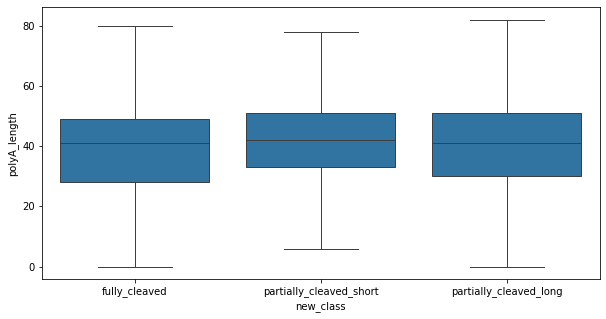

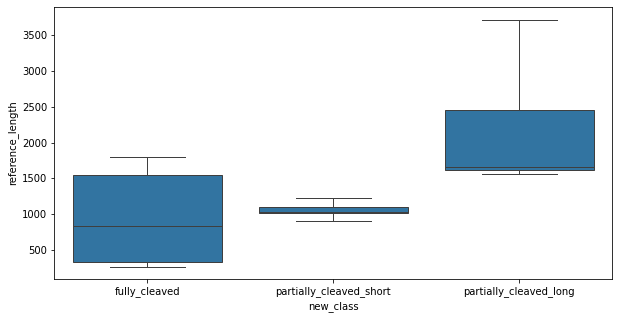

In [184]:
plt.figure(figsize=(10,5))
sn.boxplot(data=df_forw_new_class, x="new_class", y="polyA_length", showfliers=None)
plt.show()

plt.figure(figsize=(10,5))
sn.boxplot(data=df_forw_new_class, x="new_class", y="reference_length", showfliers=None)
plt.show()

In [187]:
df_forw_new_class.query("new_class == 'fully_cleaved'").overlapping_gene_names.value_counts()

MT-ND3                    9324083
MT-ATP8,MT-ATP6,MT-CO3    7604221
MT-ND4L,MT-ND4            5538249
MT-RNR2                   4777828
MT-CYB                    4717006
MT-RNR1                   1390405
MT-CO3                     762975
MT-ND4                     532761
MT-ATP8,MT-ATP6            475211
MT-ND2                     331867
MT-ND1                     243921
MT-CO1                      86428
MT-CO2                      48854
MT-ND5                      26372
MT-ND4L                      9442
MT-ATP6                      9000
MT-ATP6,MT-CO3                 22
Name: overlapping_gene_names, dtype: int64

In [188]:
df_forw_new_class.query("new_class == 'partially_cleaved_short'").overlapping_gene_names.value_counts()

MT-TL1,MT-ND1,MT-TI                          844682
MT-TM,MT-ND2,MT-TW                           307263
MT-ATP6,MT-CO3,MT-TG                         229536
MT-RNR2,MT-TL1,MT-ND1,MT-TI                  113633
MT-TR,MT-ND4L,MT-ND4                         100536
MT-TK,MT-ATP8,MT-ATP6,MT-CO3                  90044
MT-RNR2,MT-TL1,MT-ND1                         54452
MT-ATP8,MT-ATP6,MT-CO3,MT-TG                  51425
MT-TK,MT-ATP8,MT-ATP6                         38207
MT-TI,MT-TM,MT-ND2,MT-TW                      24070
MT-ND1,MT-TI,MT-TM                            23180
MT-CO1,MT-TD,MT-CO2                           20671
MT-RNR1,MT-TV,MT-RNR2                         19609
MT-ND4L,MT-ND4,MT-TH                          11818
MT-ND1,MT-TI,MT-TM,MT-ND2                      9824
MT-CO2,MT-TK,MT-ATP8,MT-ATP6,MT-CO3            9043
MT-TF,MT-RNR1,MT-TV,MT-RNR2                    8921
MT-TI,MT-TM,MT-ND2                             8362
MT-CO2,MT-TK,MT-ATP8,MT-ATP6                   7606
MT-CO3,MT-TG

In [189]:
df_forw_new_class.query("new_class == 'partially_cleaved_short' & n_overlapping_gene_ids > 4").overlapping_gene_names.value_counts()

MT-CO2,MT-TK,MT-ATP8,MT-ATP6,MT-CO3          9043
MT-ND1,MT-TI,MT-TM,MT-ND2,MT-TW              3481
MT-ND4,MT-TH,MT-TS2,MT-TL2,MT-ND5            1770
MT-CO3,MT-TG,MT-ND3,MT-TR,MT-ND4L            1766
MT-RNR2,MT-TL1,MT-ND1,MT-TI,MT-TM            1393
MT-CO3,MT-TG,MT-ND3,MT-TR,MT-ND4L,MT-ND4      762
MT-TG,MT-ND3,MT-TR,MT-ND4L,MT-ND4             550
MT-TD,MT-CO2,MT-TK,MT-ATP8,MT-ATP6            517
MT-RNR2,MT-TL1,MT-ND1,MT-TI,MT-TM,MT-ND2      463
MT-TL1,MT-ND1,MT-TI,MT-TM,MT-ND2              375
MT-CO1,MT-TD,MT-CO2,MT-TK,MT-ATP8             343
MT-CO1,MT-TD,MT-CO2,MT-TK,MT-ATP8,MT-ATP6     256
MT-ND4L,MT-ND4,MT-TH,MT-TS2,MT-TL2             88
MT-ATP6,MT-CO3,MT-TG,MT-ND3,MT-TR,MT-ND4L       5
MT-ATP6,MT-CO3,MT-TG,MT-ND3,MT-TR               2
Name: overlapping_gene_names, dtype: int64

In [190]:
df_forw_new_class.query("new_class == 'partially_cleaved_short' & n_overlapping_gene_ids == 6")

,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,sample,overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class,new_class
1668066,chrM,2954,4481,41fa696d-1af7-4bd3-bbb5-619fc8c64089,60,+,1534.0,1528,1527,46,GTA1,"ENSG00000210082.2,ENSG00000209082.1,ENSG000001...","MT-RNR2,MT-TL1,MT-ND1,MT-TI,MT-TM,MT-ND2",6,precursor_gene,partially_cleaved_short
1694766,chrM,2995,4555,69b272bd-ef46-468d-814d-8d7b49f87f7e,60,+,1554.0,1522,1560,29,GTA1,"ENSG00000210082.2,ENSG00000209082.1,ENSG000001...","MT-RNR2,MT-TL1,MT-ND1,MT-TI,MT-TM,MT-ND2",6,precursor_gene,partially_cleaved_short
1696515,chrM,2998,4552,76a69928-a267-458d-bc6a-adbcd273b3f4,60,+,1566.0,1558,1554,22,GTA1,"ENSG00000210082.2,ENSG00000209082.1,ENSG000001...","MT-RNR2,MT-TL1,MT-ND1,MT-TI,MT-TM,MT-ND2",6,precursor_gene,partially_cleaved_short
1700024,chrM,3003,4549,d72d551c-ce9f-4f82-aa9a-86012199fd8a,60,+,1563.0,1540,1546,30,GTA1,"ENSG00000210082.2,ENSG00000209082.1,ENSG000001...","MT-RNR2,MT-TL1,MT-ND1,MT-TI,MT-TM,MT-ND2",6,precursor_gene,partially_cleaved_short
1712368,chrM,3018,4555,6c2d405f-2b39-489a-8ef8-0f7f0f2578f9,60,+,1463.0,1438,1537,38,GTA1,"ENSG00000210082.2,ENSG00000209082.1,ENSG000001...","MT-RNR2,MT-TL1,MT-ND1,MT-TI,MT-TM,MT-ND2",6,precursor_gene,partially_cleaved_short
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187622194,chrM,9960,10879,cccae646-142a-4e39-82cd-3a3ef4e64559,60,+,934.0,909,919,35,GTH6,"ENSG00000198938.2,ENSG00000210164.1,ENSG000001...","MT-CO3,MT-TG,MT-ND3,MT-TR,MT-ND4L,MT-ND4",6,precursor_gene,partially_cleaved_short
187622198,chrM,9973,10856,1cf9d2b5-f04e-433b-9cfb-29b7d63e0de5,60,+,899.0,871,883,38,GTH6,"ENSG00000198938.2,ENSG00000210164.1,ENSG000001...","MT-CO3,MT-TG,MT-ND3,MT-TR,MT-ND4L,MT-ND4",6,precursor_gene,partially_cleaved_short
187622199,chrM,9976,11502,ab686c42-450a-449d-b5c1-4518154d7bb9,60,+,1529.0,1523,1526,37,GTH6,"ENSG00000198938.2,ENSG00000210164.1,ENSG000001...","MT-CO3,MT-TG,MT-ND3,MT-TR,MT-ND4L,MT-ND4",6,precursor_gene,partially_cleaved_short
194047804,chrM,3203,4554,1161ae03-957c-4efd-a703-3a23fbe92bb2,60,+,1368.0,1349,1351,35,GTH9,"ENSG00000210082.2,ENSG00000209082.1,ENSG000001...","MT-RNR2,MT-TL1,MT-ND1,MT-TI,MT-TM,MT-ND2",6,precursor_gene,partially_cleaved_short


In [191]:
df_forw_new_class.query("new_class == 'partially_cleaved_long'").n_overlapping_gene_ids.value_counts()

4     1287227
3      585769
5      102095
6       27553
7       15795
8        2078
9        1863
10       1096
11        210
12        107
14         47
13         37
17         15
16         15
15          9
18          7
21          2
20          1
Name: n_overlapping_gene_ids, dtype: int64

In [192]:
df_forw_new_class.query("new_class == 'partially_cleaved_long'").overlapping_gene_names.value_counts().index.tolist()

['MT-ATP8,MT-ATP6,MT-CO3,MT-TG',
 'MT-RNR2,MT-TL1,MT-ND1,MT-TI',
 'MT-TR,MT-ND4L,MT-ND4',
 'MT-TV,MT-RNR2,MT-TL1',
 'MT-ND4L,MT-ND4,MT-TH',
 'MT-RNR2,MT-TL1,MT-ND1',
 'MT-CO1,MT-TD,MT-CO2',
 'MT-RNR1,MT-TV,MT-RNR2,MT-TL1',
 'MT-TF,MT-RNR1,MT-TV,MT-RNR2,MT-TL1',
 'MT-RNR1,MT-TV,MT-RNR2',
 'MT-TF,MT-RNR1,MT-TV,MT-RNR2',
 'MT-TV,MT-RNR2,MT-TL1,MT-ND1,MT-TI',
 'MT-TK,MT-ATP8,MT-ATP6,MT-CO3,MT-TG',
 'MT-CO2,MT-TK,MT-ATP8,MT-ATP6,MT-CO3',
 'MT-ND1,MT-TI,MT-TM,MT-ND2,MT-TW',
 'MT-TL2,MT-ND5,MT-CYB',
 'MT-RNR1,MT-TV,MT-RNR2,MT-TL1,MT-ND1,MT-TI',
 'MT-TW,MT-CO1,MT-TD',
 'MT-ND3,MT-TR,MT-ND4L,MT-ND4',
 'MT-TV,MT-RNR2,MT-TL1,MT-ND1',
 'MT-TF,MT-RNR1,MT-TV,MT-RNR2,MT-TL1,MT-ND1,MT-TI',
 'MT-RNR2,MT-TL1,MT-ND1,MT-TI,MT-TM',
 'MT-ND5,MT-CYB,MT-TT',
 'MT-CO1,MT-TD,MT-CO2,MT-TK,MT-ATP8,MT-ATP6,MT-CO3',
 'MT-RNR2,MT-TL1,MT-ND1,MT-TI,MT-TM,MT-ND2',
 'MT-TR,MT-ND4L,MT-ND4,MT-TH',
 'MT-RNR2,MT-TL1,MT-ND1,MT-TI,MT-TM,MT-ND2,MT-TW',
 'MT-ND4L,MT-ND4,MT-TH,MT-TS2,MT-TL2',
 'MT-CO2,MT-TK,MT-ATP8,MT-ATP6,MT-CO

In [193]:
df_forw_new_class.query("new_class == 'partially_cleaved_long' & n_overlapping_gene_ids >= 18")

,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,sample,overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class,new_class
15224727,chrM,5409,13198,71d2e4d5-dca3-4f6d-852b-bced1fb2e3d1,60,+,7798.0,7770,7789,46,GTA3,"ENSG00000198763.3,ENSG00000210117.1,ENSG000001...","MT-ND2,MT-TW,MT-CO1,MT-TD,MT-CO2,MT-TK,MT-ATP8...",18,precursor_gene,partially_cleaved_long
39946911,chrM,2762,10612,1d8f5717-7966-4f8a-94a0-7cbfc9c9d23b,60,+,7850.0,7825,7850,61,GTB6,"ENSG00000210082.2,ENSG00000209082.1,ENSG000001...","MT-RNR2,MT-TL1,MT-ND1,MT-TI,MT-TM,MT-ND2,MT-TW...",18,precursor_gene,partially_cleaved_long
40307632,chrM,4635,12815,4bb02f61-bcb1-4a37-a0b4-2668fdf3132b,60,+,8179.0,8171,8180,7,GTB6,"ENSG00000198763.3,ENSG00000210117.1,ENSG000001...","MT-ND2,MT-TW,MT-CO1,MT-TD,MT-CO2,MT-TK,MT-ATP8...",18,precursor_gene,partially_cleaved_long
70721857,chrM,573,9991,b4b04ec2-270e-40b6-a25d-b4e385fb1af5,60,+,9458.0,9433,9418,41,GTD2,"ENSG00000210049.1,ENSG00000211459.2,ENSG000002...","MT-TF,MT-RNR1,MT-TV,MT-RNR2,MT-TL1,MT-ND1,MT-T...",18,precursor_gene,partially_cleaved_long
80373611,chrM,3255,11139,f97b3a01-abd6-47e9-aa81-3861f8aabf84,60,+,7856.0,7842,7884,26,GTD5,"ENSG00000209082.1,ENSG00000198888.2,ENSG000002...","MT-TL1,MT-ND1,MT-TI,MT-TM,MT-ND2,MT-TW,MT-CO1,...",18,precursor_gene,partially_cleaved_long
90572293,chrM,570,10620,eef6f8bc-2eec-4803-b61e-1fcea89fbfd4,60,+,9390.0,9357,10050,36,GTD9,"ENSG00000210049.1,ENSG00000211459.2,ENSG000002...","MT-TF,MT-RNR1,MT-TV,MT-RNR2,MT-TL1,MT-ND1,MT-T...",21,precursor_gene,partially_cleaved_long
92537730,chrM,5386,14079,0bea4114-72d5-40f4-994b-10fae8eb64c3,60,+,8660.0,8643,8693,37,GTD9,"ENSG00000198763.3,ENSG00000210117.1,ENSG000001...","MT-ND2,MT-TW,MT-CO1,MT-TD,MT-CO2,MT-TK,MT-ATP8...",18,precursor_gene,partially_cleaved_long
115829678,chrM,5115,12865,ea77431a-3762-4b25-ad51-5a55127c5573,60,+,7761.0,7722,7750,48,GTF2,"ENSG00000198763.3,ENSG00000210117.1,ENSG000001...","MT-ND2,MT-TW,MT-CO1,MT-TD,MT-CO2,MT-TK,MT-ATP8...",18,precursor_gene,partially_cleaved_long
132148873,chrM,567,10470,69576bce-77c7-498b-89e3-2075f9758175,60,+,9851.0,9828,9903,61,GTG1,"ENSG00000210049.1,ENSG00000211459.2,ENSG000002...","MT-TF,MT-RNR1,MT-TV,MT-RNR2,MT-TL1,MT-ND1,MT-T...",21,precursor_gene,partially_cleaved_long
174155530,chrM,4254,12336,3fcb25fd-68bc-408d-8d11-4d7c59e9bd42,60,+,8065.0,8029,8082,68,GTH3,"ENSG00000198888.2,ENSG00000210100.1,ENSG000002...","MT-ND1,MT-TI,MT-TM,MT-ND2,MT-TW,MT-CO1,MT-TD,M...",20,precursor_gene,partially_cleaved_long


In [194]:
df_forw_new_class["new_class"].value_counts()

fully_cleaved              35878645
partially_cleaved_short     2024678
partially_cleaved_long      2023926
Name: new_class, dtype: int64

In [201]:
df_forw_new_class.shape

(39927249, 16)

In [195]:
df_forw.shape

(182535645, 15)

In [196]:
pairs = df_forw.groupby(["ChrStart", "ChrEnd"]).size().rename("count").reset_index().sort_values("count", ascending=False)
pairs["perc"] = round(100*(pairs["count"] / pairs["count"].sum()),10)
pairs

,ChrStart,ChrEnd,count,perc
2649182,10068,10404,5305193,2.906387e+00
2501965,9215,9991,2882513,1.579151e+00
2347682,8374,9207,2552729,1.398482e+00
2227232,7596,8294,2352537,1.288810e+00
2504603,9217,9991,1810734,9.919893e-01
...,...,...,...,...
2484131,8978,9178,1,5.478000e-07
2110142,6770,7079,1,5.478000e-07
1304072,3592,3874,1,5.478000e-07
1304074,3592,3879,1,5.478000e-07


In [197]:
pairs.describe()

,ChrStart,ChrEnd,count,perc
count,4.555954e+06,4.555954e+06,4.555954e+06,4.555954e+06
mean,7.866626e+03,8.495025e+03,4.006530e+01,2.194929e-05
std,4.712580e+03,4.743381e+03,4.398383e+03,2.409602e-03
min,0.000000e+00,8.000000e+01,1.000000e+00,5.478000e-07
25%,3.133000e+03,3.748000e+03,1.000000e+00,5.478000e-07
50%,7.796000e+03,8.255000e+03,2.000000e+00,1.095700e-06
75%,1.236000e+04,1.291700e+04,5.000000e+00,2.739200e-06
max,1.648900e+04,1.656900e+04,5.305193e+06,2.906387e+00


In [198]:
pairs_count10 = pairs.query("count > 10")
pairs_count10

,ChrStart,ChrEnd,count,perc
2649182,10068,10404,5305193,2.906387
2501965,9215,9991,2882513,1.579151
2347682,8374,9207,2552729,1.398482
2227232,7596,8294,2352537,1.288810
2504603,9217,9991,1810734,0.991989
...,...,...,...,...
1316928,3631,3962,11,0.000006
4540894,16171,16318,11,0.000006
808953,2271,4268,11,0.000006
2622510,9716,9803,11,0.000006


In [199]:
pairs_count10.describe()

,ChrStart,ChrEnd,count,perc
count,548475.000000,548475.000000,5.484750e+05,548475.000000
mean,5859.634532,6422.493430,3.144561e+02,0.000172
std,4455.026766,4520.635633,1.267328e+04,0.006943
min,0.000000,96.000000,1.100000e+01,0.000006
25%,2082.000000,2617.000000,1.400000e+01,0.000008
50%,3863.000000,4267.000000,2.300000e+01,0.000013
75%,10070.000000,10299.000000,5.500000e+01,0.000030
max,16489.000000,16569.000000,5.305193e+06,2.906387
